<a href="https://colab.research.google.com/github/HorrorHERE/Colab_projects/blob/main/CrimeClasssificationSFPD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# San Francisco Crime Classification

# Задача классификации: предсказать категорию преступления (Category) на основе времени и местоположения

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split

from sklearn.metrics import log_loss

from datetime import datetime

train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

print("Размер обучающего набора:", train_df.shape)
print("Размер тестового набора:", test_df.shape)

Размер обучающего набора: (79814, 9)
Размер тестового набора: (113040, 7)


Random Forest, XGBoost и catboost не требуют масштабирования признаков. Это одно из ключевых преимуществ этих алгоритмов, так как они работают с признаками независимо друг от друга и не чувствительны к их масштабу.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79814 entries, 0 to 79813
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Dates       79814 non-null  object 
 1   Category    79813 non-null  object 
 2   Descript    79813 non-null  object 
 3   DayOfWeek   79813 non-null  object 
 4   PdDistrict  79813 non-null  object 
 5   Resolution  79813 non-null  object 
 6   Address     79813 non-null  object 
 7   X           79813 non-null  float64
 8   Y           79813 non-null  float64
dtypes: float64(2), object(7)
memory usage: 5.5+ MB


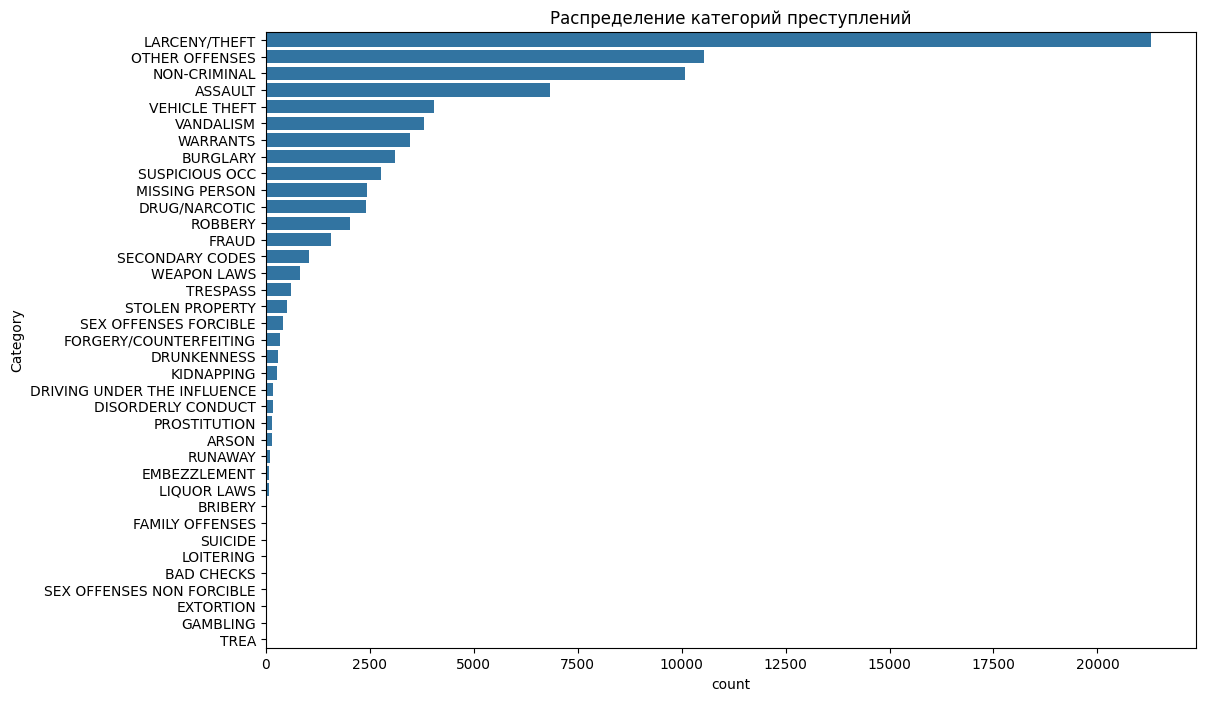

In [ ]:
train_df.head()

train_df.info()

train_df.describe(include='all')

plt.figure(figsize=(12, 8))
sns.countplot(y=train_df['Category'], order=train_df['Category'].value_counts().index)
plt.title('Распределение категорий преступлений')
plt.show()

Если посмотрим на распределение категорий распределения, то заметим, что у так называемый "дисбаланс классов" (**class imbalance**). Категории "LARCENY/THEFT" встречаются очень часто, а, например, "TREA" - вообще не встречаются, поэтому при обучении мы должны быть осторожны, чтобы модель не была сильно предвзятой. А **в задачах классификации инцидентов, преступлений, мошенничества редкие классы являются наиболее важными**

Этот код создаёт интерактивную, тепловую карту Сан-Франциско, на которой отображаются места преступлений. Сохраняется в формате HTML


In [ ]:
import pandas as pd
import numpy as np
import folium
from folium.plugins import HeatMap

# Load your data
df = pd.read_csv('train.csv')  # or 'test.csv'

print(f"Original data shape: {df.shape}")

# 1. CHECK FOR MISSING VALUES
print("\n🔍 Checking for missing coordinates...")
print(f"Missing values in X (longitude): {df['X'].isna().sum()}")
print(f"Missing values in Y (latitude): {df['Y'].isna().sum()}")

# 2. REMOVE ROWS WITH ANY MISSING COORDINATES
initial_count = len(df)
df_clean = df.dropna(subset=['X', 'Y']).copy()
removed_count = initial_count - len(df_clean)
print(f"\nRemoved {removed_count} rows with missing coordinates.")
print(f"Clean data shape: {df_clean.shape}")

# 3. ALSO HANDLE YOUR PREVIOUS BAD DATA ISSUE
# Remove the erroneous Antarctic coordinates you identified earlier
df_clean = df_clean[
    (df_clean['X'] != -120.5) &
    (df_clean['Y'] != 90.0) &
    (df_clean['X'].between(-123, -121)) &  # Valid SF longitude range
    (df_clean['Y'].between(37, 38))        # Valid SF latitude range
]
print(f"After removing bad coordinates: {df_clean.shape}")

# 4. VERIFY DATA IS CLEAN
print("\n✅ Verification:")
print(f"Missing in X: {df_clean['X'].isna().sum()}")
print(f"Missing in Y: {df_clean['Y'].isna().sum()}")
print(f"X range: [{df_clean['X'].min():.4f}, {df_clean['X'].max():.4f}]")
print(f"Y range: [{df_clean['Y'].min():.4f}, {df_clean['Y'].max():.4f}]")

# 5. PROCEED WITH MAPPING USING CLEANED DATA
print("\n🗺️ Creating map with clean data...")
SF_COORDINATES = (37.76, -122.45)
crime_map = folium.Map(location=SF_COORDINATES, zoom_start=12)

# Prepare heatmap data (Folium expects [lat, lon])
heat_data = df_clean[['Y', 'X']].values.tolist()
HeatMap(heat_data, radius=10, blur=15, max_zoom=1).add_to(crime_map)

# Save the map
crime_map.save('sf_crime_heatmap_clean.html')
print("✅ Map saved as 'sf_crime_heatmap_clean.html'")

Original data shape: (144576, 9)

🔍 Checking for missing coordinates...
Missing values in X (longitude): 0
Missing values in Y (latitude): 1

Removed 1 rows with missing coordinates.
Clean data shape: (144575, 9)
After removing bad coordinates: (144575, 9)

✅ Verification:
Missing in X: 0
Missing in Y: 0
X range: [-122.5136, -122.3652]
Y range: [37.7079, 37.8200]

🗺️ Creating map with clean data...
✅ Map saved as 'sf_crime_heatmap_clean.html'


In [ ]:
import pandas as pd
import folium
from folium.plugins import MarkerCluster
import random

In [ ]:

import pandas as pd
import folium
from folium.plugins import MarkerCluster

df = pd.read_csv('train.csv')

df['X'] = pd.to_numeric(df['X'], errors='coerce')
df['Y'] = pd.to_numeric(df['Y'], errors='coerce')

df_clean = df.dropna(subset=['X', 'Y']).copy()
df_clean = df_clean[
    (df_clean['X'].between(-123, -121)) &
    (df_clean['Y'].between(37, 38))
]

top_categories = df_clean['Category'].value_counts().head(10).index.tolist()
df_top = df_clean[df_clean['Category'].isin(top_categories)].copy()

color_palette = ['red', 'blue', 'green', 'purple', 'orange', 'darkred', 'lightblue', 'pink', 'gray', 'black']
category_colors = {cat: color_palette[i] for i, cat in enumerate(top_categories)}

sf_coordinates = (37.76, -122.45)
crime_map = folium.Map(location=sf_coordinates, zoom_start=12)

for category, color in category_colors.items():
    category_data = df_top[df_top['Category'] == category]
    cluster = MarkerCluster(name=category).add_to(crime_map)

    for _, row in category_data.iterrows():
        folium.CircleMarker(
            location=[row['Y'], row['X']],
            radius=3,
            color=color,
            fill=True,
            fill_opacity=0.6,
            popup=f"Категория: {category}"
        ).add_to(cluster)

legend_html = '''
<div style="
    position: fixed;
    bottom: 50px;
    left: 50px;
    width: 200px;
    background: white;
    border: 2px solid grey;
    z-index: 9999;
    padding: 10px;
    font-size: 12px;
">
<b>Легенда</b><br>
'''

for cat, color in category_colors.items():
    legend_html += f'<i style="background:{color}; width:12px; height:12px; display:inline-block; margin-right:5px;"></i> {cat}<br>'

legend_html += '</div>'
crime_map.get_root().html.add_child(folium.Element(legend_html))

crime_map.save('sf_crime_by_category.html')
print(f"Карта сохранена.  Категориb: {len(top_categories)}")

KeyboardInterrupt: 

## Преобразование строкового представления времени в отдельные числовые признаки

В данном сегменте выполения задачи классификации нами была создана фунекция, которая превращает необработанные временные метки в временные признаки с указанием к какому участку полиции относится преступление

In [ ]:
def create_time_features(df):
    df['Dates'] = pd.to_datetime(df['Dates'])
    df['Year'] = df['Dates'].dt.year
    df['Month'] = df['Dates'].dt.month
    df['Day'] = df['Dates'].dt.day
    df['Hour'] = df['Dates'].dt.hour
    df['Minute'] = df['Dates'].dt.minute
    df['DayOfWeek'] = df['Dates'].dt.dayofweek
    df['IsWeekend'] = df['DayOfWeek'].isin([5, 6]).astype(int)
    return df

train_df = create_time_features(train_df)
test_df = create_time_features(test_df)

categorical_columns = ['DayOfWeek', 'PdDistrict']

from sklearn.preprocessing import LabelEncoder

label_encoders = {}

for col in categorical_columns:
    le = LabelEncoder()
    le.fit(train_df[col].astype(str))
    label_encoders[col] = le
    train_df[col] = le.transform(train_df[col].astype(str))
    test_df[col] = le.transform(test_df[col].astype(str))

feature_columns = ['X', 'Y', 'Year', 'Month', 'Day', 'Hour', 'Minute', 'DayOfWeek', 'IsWeekend', 'PdDistrict']
X = train_df[feature_columns]
y = train_df['Category']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Типы признаков:")
print(X_train.dtypes)
print(X_train.head)

Типы признаков:
X             float64
Y             float64
Year            int32
Month           int32
Day             int32
Hour            int32
Minute          int32
DayOfWeek       int64
IsWeekend       int64
PdDistrict      int64
dtype: object
<bound method NDFrame.head of                  X          Y  Year  Month  Day  Hour  Minute  DayOfWeek  \
42328  -122.400904  37.752101  2014     10   18     2      30          5   
778286 -122.430437  37.772107  2004      5    1     0      30          5   
625961 -122.420602  37.762928  2006      6   28    16      45          2   
419817 -122.425111  37.804146  2009      6   14    22       0          6   
369198 -122.412899  37.785097  2010      3   24    14      38          2   
...            ...        ...   ...    ...  ...   ...     ...        ...   
198308 -122.403405  37.775421  2012      9   23    11       0          6   
296594 -122.436911  37.787067  2011      4   20    11      50          2   
449101 -122.414302  37.781863  2009 

## Random Forest Classifier


### Обучение

In [ ]:
# Модель Random Forest (rf_model)
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1  # все процессоры использовать для обучения.
)

print("Обучение Random Forest...")
rf_model.fit(X_train, y_train)

y_val_proba_rf = rf_model.predict_proba(X_val)

logloss_rf = log_loss(y_val, y_val_proba_rf)
print(f"LogLoss Random Forest на валидации: {logloss_rf:.6f}")

Обучение Random Forest...
LogLoss Random Forest на валидации: 2.328042


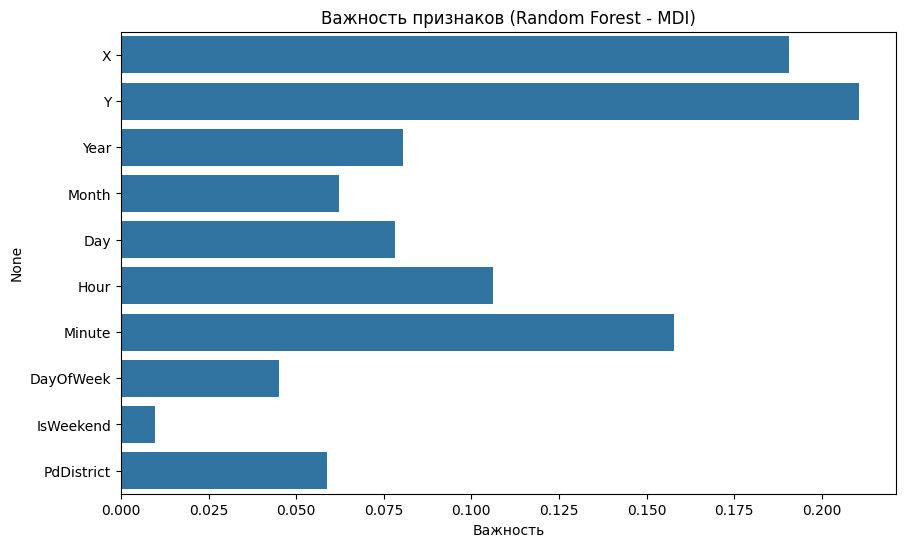

In [ ]:
feature_importances_rf = rf_model.feature_importances_
features_rf = X_train.columns
plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importances_rf, y=features_rf)
plt.title('Важность признаков (Random Forest - MDI)')
plt.xlabel('Важность')
plt.show()

Чтобы вычислить accuracy для каждой категории преступлений нам нужно сделать предсказания по валидационному набору данных, используя уже обуученую модель Random Forest

In [ ]:
y_pred= rf_model.predict(X_val)

Теперь, когда предсказания для валидационного набора сгенерированы -
рассчитаем  точность для каждой категории преступлений, сравнив предсказанные значения (y_pred) с истинными значениями (y_val). Для этого нужно пройтись по каждой  категории, отфильтровать предсказания и истинные метки для этой категории и вычислить точность

In [ ]:
from sklearn.metrics import accuracy_score

category_accuracies = {}
unique_categories = y_val.unique()

for category in unique_categories:
    # Фильтруем для текущей категории в y_val
    category_indices = y_val[y_val == category].index
    y_val_category = y_val.loc[category_indices]
    y_pred_category = pd.Series(y_pred, index=y_val.index).loc[category_indices]


    correct_predictions = (y_val_category == y_pred_category).sum()
    total_predictions = len(y_val_category)

    if total_predictions > 0:
        accuracy = correct_predictions / total_predictions
        category_accuracies[category] = accuracy
    else:
        category_accuracies[category] = 0.0 # No instances for this category in validation set

# создаем dataframe из новых значений accuracy
accuracy_df = pd.DataFrame(list(category_accuracies.items()), columns=['Категория Преступления', 'Точность'])

# Сортируем по точности
accuracy_df = accuracy_df.sort_values(by='Точность', ascending=False).reset_index(drop=True)

print("Точность по каждой категории преступления:")
print(accuracy_df)

Точность по каждой категории преступления:
         Категория Преступления  Точность
0                 LARCENY/THEFT  0.780760
1                  PROSTITUTION  0.641283
2                OTHER OFFENSES  0.503329
3                 DRUG/NARCOTIC  0.422086
4                 VEHICLE THEFT  0.285701
5                MISSING PERSON  0.211427
6                  NON-CRIMINAL  0.108391
7                       ASSAULT  0.084228
8                     LOITERING  0.016327
9                         FRAUD  0.014988
10                     BURGLARY  0.010611
11                      RUNAWAY  0.010283
12        SEX OFFENSES FORCIBLE  0.006834
13       FORGERY/COUNTERFEITING  0.006598
14                    VANDALISM  0.006260
15                     TRESPASS  0.006143
16                     WARRANTS  0.006041
17                  WEAPON LAWS  0.004091
18           DISORDERLY CONDUCT  0.003472
19               SUSPICIOUS OCC  0.001114
20                      ROBBERY  0.000870
21              SECONDARY CODES  

## Выгрузка результатов

In [ ]:
test_proba = rf_model.predict_proba(test_df[feature_columns])

submission = pd.DataFrame(test_proba, columns=rf_model.classes_)
submission.insert(0, 'Id', test_df['Id'])

submission.iloc[:, 1:].sum(axis=1).describe()

submission.to_csv('submission_rf_model.csv', index=False)

print("Файл submission_rf_model.csv успешно создан!")
print("Первые 5 строк файла:")
print(submission.head())

Файл submission_rf_model.csv успешно создан!
Первые 5 строк файла:
   Id     ARSON   ASSAULT  BAD CHECKS   BRIBERY  BURGLARY  DISORDERLY CONDUCT  \
0   0  0.003172  0.099470    0.000000  0.000512  0.032362            0.001595   
1   1  0.003041  0.112398    0.000000  0.000911  0.009823            0.002882   
2   2  0.009089  0.128390    0.000415  0.000041  0.038447            0.000586   
3   3  0.001567  0.111891    0.000003  0.001539  0.011764            0.002589   
4   4  0.001567  0.111891    0.000003  0.001539  0.011764            0.002589   

   DRIVING UNDER THE INFLUENCE  DRUG/NARCOTIC  DRUNKENNESS  ...  \
0                     0.007064       0.041022     0.003570  ...   
1                     0.004896       0.073663     0.004630  ...   
2                     0.005882       0.039637     0.014724  ...   
3                     0.011854       0.044087     0.006490  ...   
4                     0.011854       0.044087     0.006490  ...   

   SEX OFFENSES NON FORCIBLE  STOLEN PROPER

Выведем 5 наиболее вероятных категорий, которые предсказаны моделью

In [ ]:
test_instance = pd.DataFrame({
    'X': [-122.41],
    'Y': [37.78],
    'Year': [2023],
    'Month': [5],
    'Day': [15],
    'Hour': [15],
    'Minute': [30],
    'DayOfWeek': [1],
    'IsWeekend': [0],
    'PdDistrict': ['SOUTHERN']
})

for col in categorical_columns:
    test_instance[col] = label_encoders[col].transform(test_instance[col].astype(str))

probabilities = rf_model.predict_proba(test_instance[feature_columns])

predicted_class = rf_model.classes_[np.argmax(probabilities)]
max_probability = np.max(probabilities)

print(f"Наиболее вероятная категория: {predicted_class}")
print(f"Вероятность: {max_probability:.4f}")
print("Топ-5 вероятностей:")
top_5_indices = np.argsort(probabilities[0])[::-1][:5]
for idx in top_5_indices:
    print(f"  {rf_model.classes_[idx]}: {probabilities[0][idx]:.4f}")

Наиболее вероятная категория: LARCENY/THEFT
Вероятность: 0.3750
Топ-5 вероятностей:
  LARCENY/THEFT: 0.3750
  OTHER OFFENSES: 0.1750
  NON-CRIMINAL: 0.1500
  ASSAULT: 0.1000
  WARRANTS: 0.0750


In [ ]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 4.0 MB/s eta 0:00:00


## CatBoost модель


CatBoost - это по сути градиентный бустинг над деревьями (последовательное обучение деревьев, каждое исправляет ошибки предыдущего). Гораздо лучше RF на сложных задачах, но медленнее. RF - это независимые деревья, а в случае CatBoost - последовательные деревья, исправляющие ошибки друг друга, что конечно же увеличивает точность

### Обучение модели


In [ ]:
from catboost import CatBoostClassifier

# Модель CatBoost (catboost_model)
catboost_model = CatBoostClassifier(
    iterations=20,
    learning_rate=0.1,
    depth=3,
    loss_function='MultiClass',
    random_seed=42,
    verbose=100
)


print("Обучение CatBoost...")
catboost_model.fit(X_train, y_train)

y_val_proba_catboost = catboost_model.predict_proba(X_val)

logloss_catboost = log_loss(y_val, y_val_proba_catboost)
print(f"LogLoss CatBoost на валидации: {logloss_catboost:.6f}")

Обучение CatBoost...
0:	learn: 3.3404449	total: 2.06s	remaining: 39.1s
19:	learn: 2.5668760	total: 35.8s	remaining: 0us
LogLoss CatBoost на валидации: 2.566906


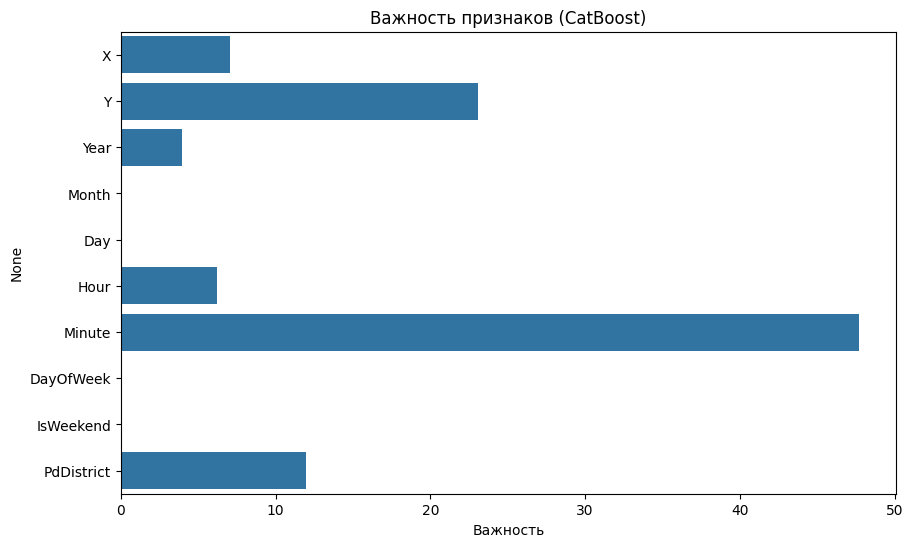

In [ ]:
feature_importances_catboost = catboost_model.get_feature_importance()
features_catboost = X_train.columns
plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importances_catboost, y=features_catboost)
plt.title('Важность признаков (CatBoost)')
plt.xlabel('Важность')
plt.show()

In [ ]:
test_proba = catboost_model.predict_proba(test_df[feature_columns])

submission = pd.DataFrame(test_proba, columns=catboost_model.classes_)
submission.insert(0, 'Id', test_df['Id'])

submission.iloc[:, 1:].sum(axis=1).describe()

submission.to_csv('submission_catboost.csv', index=False)

print("Файл submission_catboost.csv успешно создан!")
print("Первые 5 строк файла:")
print(submission.head())

Файл submission_catboost.csv успешно создан!
Первые 5 строк файла:
   Id     ARSON   ASSAULT  BAD CHECKS   BRIBERY  BURGLARY  DISORDERLY CONDUCT  \
0   0  0.005451  0.107516    0.003518  0.003741  0.022784            0.007641   
1   1  0.005451  0.107516    0.003518  0.003741  0.022784            0.007641   
2   2  0.004743  0.076387    0.003618  0.003607  0.041388            0.007072   
3   3  0.005193  0.099597    0.003609  0.003784  0.030530            0.006999   
4   4  0.005193  0.099597    0.003609  0.003784  0.030530            0.006999   

   DRIVING UNDER THE INFLUENCE  DRUG/NARCOTIC  DRUNKENNESS  ...  \
0                     0.006351       0.065192     0.008788  ...   
1                     0.006351       0.065192     0.008788  ...   
2                     0.006950       0.046018     0.008793  ...   
3                     0.006909       0.045607     0.008670  ...   
4                     0.006909       0.045607     0.008670  ...   

   SEX OFFENSES NON FORCIBLE  STOLEN PROPER

In [ ]:
test_instance = pd.DataFrame({
    'X': [-122.41],
    'Y': [37.78],
    'Year': [2023],
    'Month': [5],
    'Day': [15],
    'Hour': [15],
    'Minute': [30],
    'DayOfWeek': [1],
    'IsWeekend': [0],
    'PdDistrict': ['SOUTHERN']
})

for col in categorical_columns:
    test_instance[col] = label_encoders[col].transform(test_instance[col].astype(str))

probabilities = catboost_model.predict_proba(test_instance[feature_columns])

predicted_class = catboost_model.classes_[np.argmax(probabilities)]
max_probability = np.max(probabilities)

print(f"Наиболее вероятная категория: {predicted_class}")
print(f"Вероятность: {max_probability:.4f}")
print("Топ-5 вероятностей:")
top_5_indices = np.argsort(probabilities[0])[::-1][:5]
for idx in top_5_indices:
    print(f"  {catboost_model.classes_[idx]}: {probabilities[0][idx]:.4f}")

Наиболее вероятная категория: LARCENY/THEFT
Вероятность: 0.2031
Топ-5 вероятностей:
  LARCENY/THEFT: 0.2031
  NON-CRIMINAL: 0.1099
  OTHER OFFENSES: 0.1091
  ASSAULT: 0.0790
  DRUG/NARCOTIC: 0.0715


 Признаки c индексами 7 (DayOfWeek) и 9 (PdDistrict) являются категориальными. CatBoost сам может обработать их, что позволт ему эффективно работать c ними работат.
 Используем cat_features

In [ ]:
catboost_model = CatBoostClassifier(
    iterations=50,
    learning_rate=0.1,
    depth=3,
    loss_function='MultiClass',
    cat_features=[7, 9],  # DayOfWeek (7), PdDistrict (9)
    random_seed=42,
    verbose=100
)

print("Обучение CatBoost...")
catboost_model.fit(X_train, y_train)

y_val_proba_catboost = catboost_model.predict_proba(X_val)

logloss_catboost = log_loss(y_val, y_val_proba_catboost)
print(f"LogLoss CatBoost на валидации: {logloss_catboost:.6f}")

Обучение CatBoost...
0:	learn: 3.3459712	total: 53.2s	remaining: 43m 27s
49:	learn: 2.4849438	total: 27m 54s	remaining: 0us
LogLoss CatBoost на валидации: 2.485700


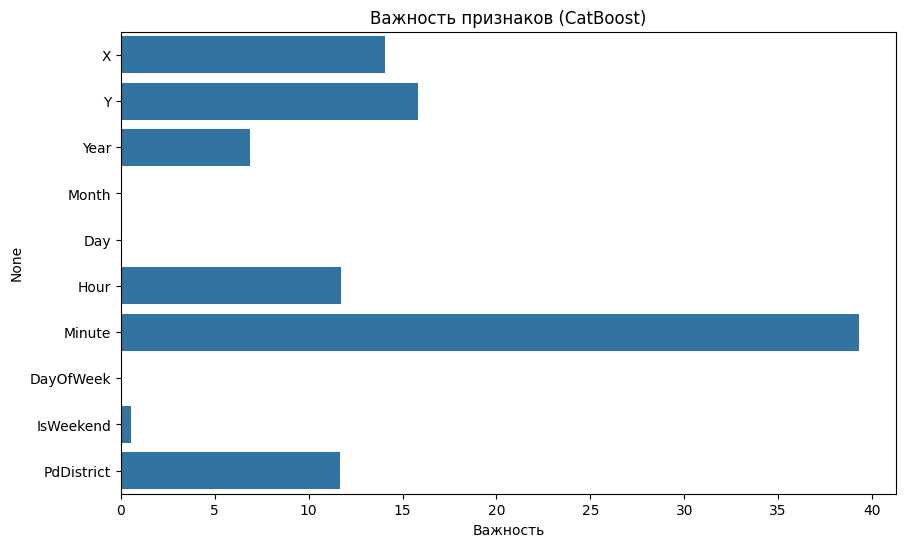

In [ ]:
feature_importances_catboost = catboost_model.get_feature_importance()
features_catboost = X_train.columns
plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importances_catboost, y=features_catboost)
plt.title('Важность признаков (CatBoost)')
plt.xlabel('Важность')
plt.show()

In [ ]:
test_proba = catboost_model.predict_proba(test_df[feature_columns])

submission = pd.DataFrame(test_proba, columns=catboost_model.classes_)
submission.insert(0, 'Id', test_df['Id'])

submission.iloc[:, 1:].sum(axis=1).describe()

submission.to_csv('submission_catboost_22.csv', index=False)

print("Файл submission_catboost_2.csv успешно создан!")
print("Первые 5 строк файла:")
print(submission.head())

Файл submission_catboost_2.csv успешно создан!
Первые 5 строк файла:
   Id     ARSON   ASSAULT  BAD CHECKS   BRIBERY  BURGLARY  DISORDERLY CONDUCT  \
0   0  0.003321  0.122372    0.000369  0.000828  0.020193            0.003167   
1   1  0.003321  0.122372    0.000369  0.000828  0.020193            0.003167   
2   2  0.001751  0.081436    0.000422  0.000477  0.042858            0.003002   
3   3  0.002487  0.117294    0.000400  0.000769  0.029680            0.002825   
4   4  0.002487  0.117294    0.000400  0.000769  0.029680            0.002825   

   DRIVING UNDER THE INFLUENCE  DRUG/NARCOTIC  DRUNKENNESS  ...  \
0                     0.004471       0.060350     0.005999  ...   
1                     0.004471       0.060350     0.005999  ...   
2                     0.004476       0.033778     0.006924  ...   
3                     0.004509       0.035467     0.005213  ...   
4                     0.004509       0.035467     0.005213  ...   

   SEX OFFENSES NON FORCIBLE  STOLEN PROP

In [ ]:
test_instance = pd.DataFrame({
    'X': [-122.41],
    'Y': [37.78],
    'Year': [2023],
    'Month': [5],
    'Day': [15],
    'Hour': [15],
    'Minute': [30],
    'DayOfWeek': [1],
    'IsWeekend': [0],
    'PdDistrict': ['SOUTHERN']
})

for col in categorical_columns:
    test_instance[col] = label_encoders[col].transform(test_instance[col].astype(str))

probabilities = catboost_model.predict_proba(test_instance[feature_columns])

predicted_class = catboost_model.classes_[np.argmax(probabilities)]
max_probability = np.max(probabilities)

print(f"Наиболее вероятная категория: {predicted_class}")
print(f"Вероятность: {max_probability:.4f}")
print("Топ-5 вероятностей:")
top_5_indices = np.argsort(probabilities[0])[::-1][:5]
for idx in top_5_indices:
    print(f"  {catboost_model.classes_[idx]}: {probabilities[0][idx]:.4f}")

Наиболее вероятная категория: LARCENY/THEFT
Вероятность: 0.2031
Топ-5 вероятностей:
  LARCENY/THEFT: 0.2031
  NON-CRIMINAL: 0.1099
  OTHER OFFENSES: 0.1091
  ASSAULT: 0.0790
  DRUG/NARCOTIC: 0.0715


In [ ]:
test_instance = pd.DataFrame({
    'X': [-122.41],
    'Y': [37.78],
    'Year': [2023],
    'Month': [5],
    'Day': [15],
    'Hour': [15],
    'Minute': [19],
    'DayOfWeek': [1],
    'IsWeekend': [0],
    'PdDistrict': ['SOUTHERN']
})

for col in categorical_columns:
    test_instance[col] = label_encoders[col].transform(test_instance[col].astype(str))

probabilities = catboost_model.predict_proba(test_instance[feature_columns])

predicted_class = catboost_model.classes_[np.argmax(probabilities)]
max_probability = np.max(probabilities)

print(f"Наиболее вероятная категория: {predicted_class}")
print(f"Вероятность: {max_probability:.4f}")
print("Топ-5 вероятностей:")
top_5_indices = np.argsort(probabilities[0])[::-1][:5]
for idx in top_5_indices:
    print(f"  {catboost_model.classes_[idx]}: {probabilities[0][idx]:.4f}")

Наиболее вероятная категория: OTHER OFFENSES
Вероятность: 0.1611
Топ-5 вероятностей:
  OTHER OFFENSES: 0.1611
  LARCENY/THEFT: 0.1224
  DRUG/NARCOTIC: 0.1166
  NON-CRIMINAL: 0.1046
  ASSAULT: 0.0834


In [ ]:
test_instance = pd.DataFrame({
    'X': [-122.43],
    'Y': [37.76],
    'Year': [2023],
    'Month': [5],
    'Day': [29],
    'Hour': [20],
    'Minute': [30],
    'DayOfWeek': [0],
    'IsWeekend': [1],
    'PdDistrict': ['MISSION']
})

for col in categorical_columns:
    test_instance[col] = label_encoders[col].transform(test_instance[col].astype(str))

probabilities = catboost_model.predict_proba(test_instance[feature_columns])

predicted_class = catboost_model.classes_[np.argmax(probabilities)]
max_probability = np.max(probabilities)

print(f"Наиболее вероятная категория: {predicted_class}")
print(f"Вероятность: {max_probability:.4f}")
print("Топ-5 вероятностей:")
top_5_indices = np.argsort(probabilities[0])[::-1][:5]
for idx in top_5_indices:
    print(f"  {catboost_model.classes_[idx]}: {probabilities[0][idx]:.4f}")

Наиболее вероятная категория: LARCENY/THEFT
Вероятность: 0.2090
Топ-5 вероятностей:
  LARCENY/THEFT: 0.2090
  OTHER OFFENSES: 0.1026
  NON-CRIMINAL: 0.1026
  ASSAULT: 0.0821
  VEHICLE THEFT: 0.0781


LogLoss CatBoost на тестовом наборе: 2.484868
Accuracy CatBoost на тестовом наборе: 0.2597
F1-score (micro) CatBoost на тестовом наборе: 0.2597
F1-score (macro) CatBoost на тестовом наборе: 0.0315


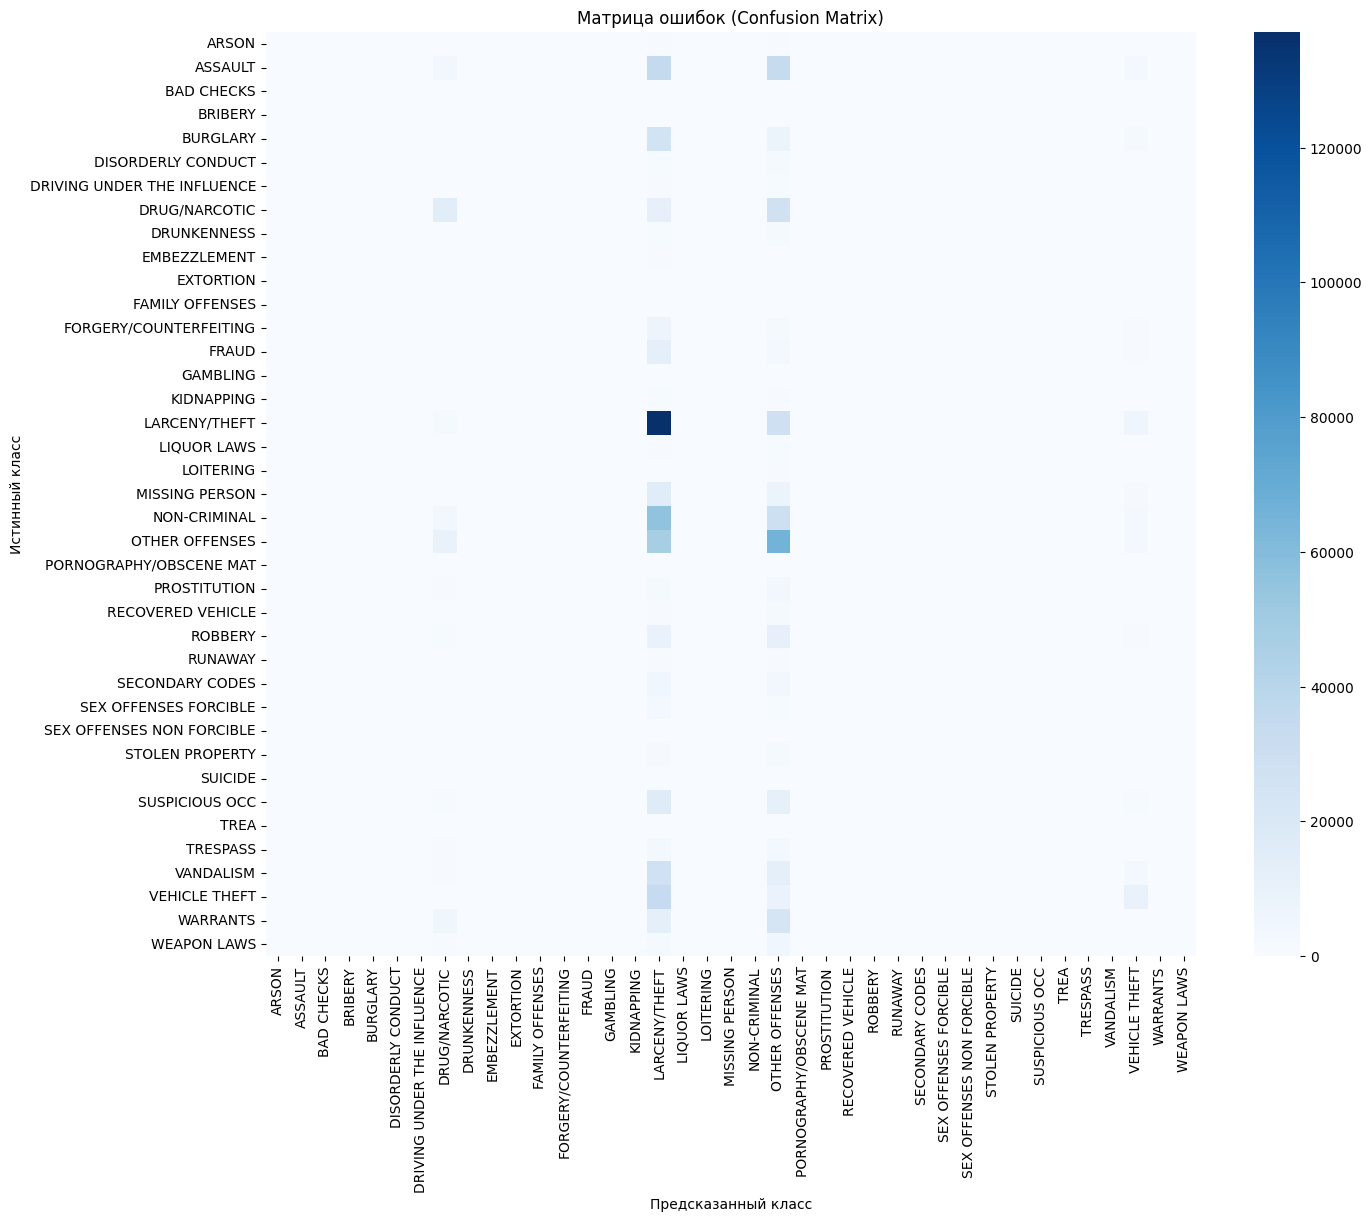

In [ ]:
from sklearn.metrics import log_loss, accuracy_score, f1_score, confusion_matrix
test_with_labels_df = pd.read_csv('train.csv')

test_with_labels_df = create_time_features(test_with_labels_df)

for col in categorical_columns:
    test_with_labels_df[col] = label_encoders[col].transform(test_with_labels_df[col].astype(str))

X_test_with_labels = test_with_labels_df[feature_columns]
y_test_true = test_with_labels_df['Category']

y_test_proba = catboost_model.predict_proba(X_test_with_labels)
y_test_pred = catboost_model.predict(X_test_with_labels)

logloss_test = log_loss(y_test_true, y_test_proba)
accuracy = accuracy_score(y_test_true, y_test_pred)
f1_micro = f1_score(y_test_true, y_test_pred, average='micro')
f1_macro = f1_score(y_test_true, y_test_pred, average='macro')

print(f"LogLoss CatBoost на тестовом наборе: {logloss_test:.6f}")
print(f"Accuracy CatBoost на тестовом наборе: {accuracy:.4f}")

print(f"F1-score (micro) CatBoost на тестовом наборе: {f1_micro:.4f}")

print(f"F1-score (macro) CatBoost на тестовом наборе: {f1_macro:.4f}")

unique_classes = catboost_model.classes_
cm = confusion_matrix(y_test_true, y_test_pred, labels=unique_classes)

plt.figure(figsize=(15, 12))
sns.heatmap(cm, annot=False, fmt='d', cmap='Blues',
            xticklabels=unique_classes, yticklabels=unique_classes)

plt.title('Матрица ошибок (Confusion Matrix)')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')


plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

### Веса для классов

Проведем автоматический расчет весов класса. Редкий класс - большой вес, частый класс - маленький вес

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

class_weights_dict = dict(zip(np.unique(y_train), class_weights))

print("Веса для классов:")
for cls, weight in class_weights_dict.items():
    print(f"{cls}: {weight:.4f}")

Веса для классов:
ARSON: 14.8853
ASSAULT: 0.2929
BAD CHECKS: 55.4193
BRIBERY: 77.9708
BURGLARY: 0.6125
DISORDERLY CONDUCT: 5.2116
DRIVING UNDER THE INFLUENCE: 9.9290
DRUG/NARCOTIC: 0.4171
DRUNKENNESS: 5.2603
EMBEZZLEMENT: 19.3047
EXTORTION: 87.8598
FAMILY OFFENSES: 45.8302
FORGERY/COUNTERFEITING: 2.1222
FRAUD: 1.3499
GAMBLING: 153.9424
KIDNAPPING: 9.6163
LARCENY/THEFT: 0.1287
LIQUOR LAWS: 11.8339
LOITERING: 18.3788
MISSING PERSON: 0.8663
NON-CRIMINAL: 0.2439
OTHER OFFENSES: 0.1784
PORNOGRAPHY/OBSCENE MAT: 1000.6254
PROSTITUTION: 3.0084
RECOVERED VEHICLE: 7.1758
ROBBERY: 0.9789
RUNAWAY: 11.5679
SECONDARY CODES: 2.2548
SEX OFFENSES FORCIBLE: 5.1314
SEX OFFENSES NON FORCIBLE: 151.3551
STOLEN PROPERTY: 4.9590
SUICIDE: 44.3627
SUSPICIOUS OCC: 0.7167
TREA: 3602.2513
TRESPASS: 3.0731
VANDALISM: 0.5034
VEHICLE THEFT: 0.4186
WARRANTS: 0.5333
WEAPON LAWS: 2.6317


In [ ]:
catboost_model = CatBoostClassifier(
    iterations=20,
    learning_rate=0.1,
    depth=3,
    loss_function='MultiClass',
    cat_features=[7, 9],  # DayOfWeek (7), PdDistrict (9)
    class_weights=class_weights,
    random_seed=42,
    verbose=100
)

print("Обучение CatBoost с взвешиванием классов...")
catboost_model.fit(X_train, y_train)

Обучение CatBoost с взвешиванием классов...
0:	learn: 3.6405130	total: 54.4s	remaining: 17m 12s
19:	learn: 3.4710815	total: 11m 45s	remaining: 0us


In [ ]:
y_val_proba_catboost = catboost_model.predict_proba(X_val)
logloss_catboost = log_loss(y_val, y_val_proba_catboost)
print(f"LogLoss CatBoost (с взвешиванием) на валидации: {logloss_catboost:.6f}")

LogLoss CatBoost (с взвешиванием) на валидации: 3.575176


In [ ]:
test_instance = pd.DataFrame({
    'X': [-122.425891675136],
    'Y': [37.7745985956747],
    'Year': [2015],
    'Month': [5],
    'Day': [13],
    'Hour': [23],
    'Minute': [53],
    'DayOfWeek': [2],
    'IsWeekend': [0],
    'PdDistrict': ['NORTHERN']
})

for col in categorical_columns:
    test_instance[col] = label_encoders[col].transform(test_instance[col].astype(str))

probabilities = catboost_model.predict_proba(test_instance[feature_columns])

predicted_class = catboost_model.classes_[np.argmax(probabilities)]
max_probability = np.max(probabilities)

print(f"Наиболее вероятная категория: {predicted_class}")
print(f"Вероятность: {max_probability:.4f}")
print("Топ-5 вероятностей:")
top_5_indices = np.argsort(probabilities[0])[::-1][:5]
for idx in top_5_indices:
    print(f"  {catboost_model.classes_[idx]}: {probabilities[0][idx]:.4f}")

Наиболее вероятная категория: STOLEN PROPERTY
Вероятность: 0.0335
Топ-5 вероятностей:
  STOLEN PROPERTY: 0.0335
  NON-CRIMINAL: 0.0305
  LARCENY/THEFT: 0.0298
  DRIVING UNDER THE INFLUENCE: 0.0293
  RUNAWAY: 0.0289


In [ ]:
test_instance = pd.DataFrame({
    'X': [-122.41],
    'Y': [37.78],
    'Year': [2023],
    'Month': [5],
    'Day': [15],
    'Hour': [15],
    'Minute': [30],
    'DayOfWeek': [1],
    'IsWeekend': [0],
    'PdDistrict': ['SOUTHERN']
})

for col in categorical_columns:
    test_instance[col] = label_encoders[col].transform(test_instance[col].astype(str))

probabilities = catboost_model.predict_proba(test_instance[feature_columns])

predicted_class = catboost_model.classes_[np.argmax(probabilities)]
max_probability = np.max(probabilities)

print(f"Наиболее вероятная категория: {predicted_class}")
print(f"Вероятность: {max_probability:.4f}")
print("Топ-5 вероятностей:")
top_5_indices = np.argsort(probabilities[0])[::-1][:5]
for idx in top_5_indices:
    print(f"  {catboost_model.classes_[idx]}: {probabilities[0][idx]:.4f}")

Наиболее вероятная категория: STOLEN PROPERTY
Вероятность: 0.0392
Топ-5 вероятностей:
  STOLEN PROPERTY: 0.0392
  LARCENY/THEFT: 0.0372
  NON-CRIMINAL: 0.0343
  TRESPASS: 0.0329
  WARRANTS: 0.0327


In [ ]:
test_instance = pd.DataFrame({
    'X': [-122.41],
    'Y': [37.78],
    'Year': [2023],
    'Month': [5],
    'Day': [15],
    'Hour': [15],
    'Minute': [19],
    'DayOfWeek': [1],
    'IsWeekend': [0],
    'PdDistrict': ['SOUTHERN']
})

for col in categorical_columns:
    test_instance[col] = label_encoders[col].transform(test_instance[col].astype(str))

probabilities = catboost_model.predict_proba(test_instance[feature_columns])

predicted_class = catboost_model.classes_[np.argmax(probabilities)]
max_probability = np.max(probabilities)

print(f"Наиболее вероятная категория: {predicted_class}")
print(f"Вероятность: {max_probability:.4f}")
print("Топ-5 вероятностей:")
top_5_indices = np.argsort(probabilities[0])[::-1][:5]
for idx in top_5_indices:
    print(f"  {catboost_model.classes_[idx]}: {probabilities[0][idx]:.4f}")

Наиболее вероятная категория: STOLEN PROPERTY
Вероятность: 0.0392
Топ-5 вероятностей:
  STOLEN PROPERTY: 0.0392
  LARCENY/THEFT: 0.0372
  NON-CRIMINAL: 0.0343
  TRESPASS: 0.0329
  WARRANTS: 0.0327


In [ ]:
test_instance = pd.DataFrame({
    'X': [-122.43],
    'Y': [37.76],
    'Year': [2023],
    'Month': [5],
    'Day': [29],
    'Hour': [20],
    'Minute': [30],
    'DayOfWeek': [0],
    'IsWeekend': [1],
    'PdDistrict': ['MISSION']
})

for col in categorical_columns:
    test_instance[col] = label_encoders[col].transform(test_instance[col].astype(str))

probabilities = catboost_model.predict_proba(test_instance[feature_columns])

predicted_class = catboost_model.classes_[np.argmax(probabilities)]
max_probability = np.max(probabilities)

print(f"Наиболее вероятная категория: {predicted_class}")
print(f"Вероятность: {max_probability:.4f}")
print("Топ-5 вероятностей:")
top_5_indices = np.argsort(probabilities[0])[::-1][:5]
for idx in top_5_indices:
    print(f"  {catboost_model.classes_[idx]}: {probabilities[0][idx]:.4f}")

Наиболее вероятная категория: BRIBERY
Вероятность: 0.0355
Топ-5 вероятностей:
  BRIBERY: 0.0355
  PROSTITUTION: 0.0321
  RUNAWAY: 0.0307
  WEAPON LAWS: 0.0303
  DRIVING UNDER THE INFLUENCE: 0.0302


LogLoss CatBoost на тестовом наборе: 3.574781
Accuracy CatBoost на тестовом наборе: 0.0539
F1-score (micro) CatBoost на тестовом наборе: 0.0539
F1-score (macro) CatBoost на тестовом наборе: 0.0239


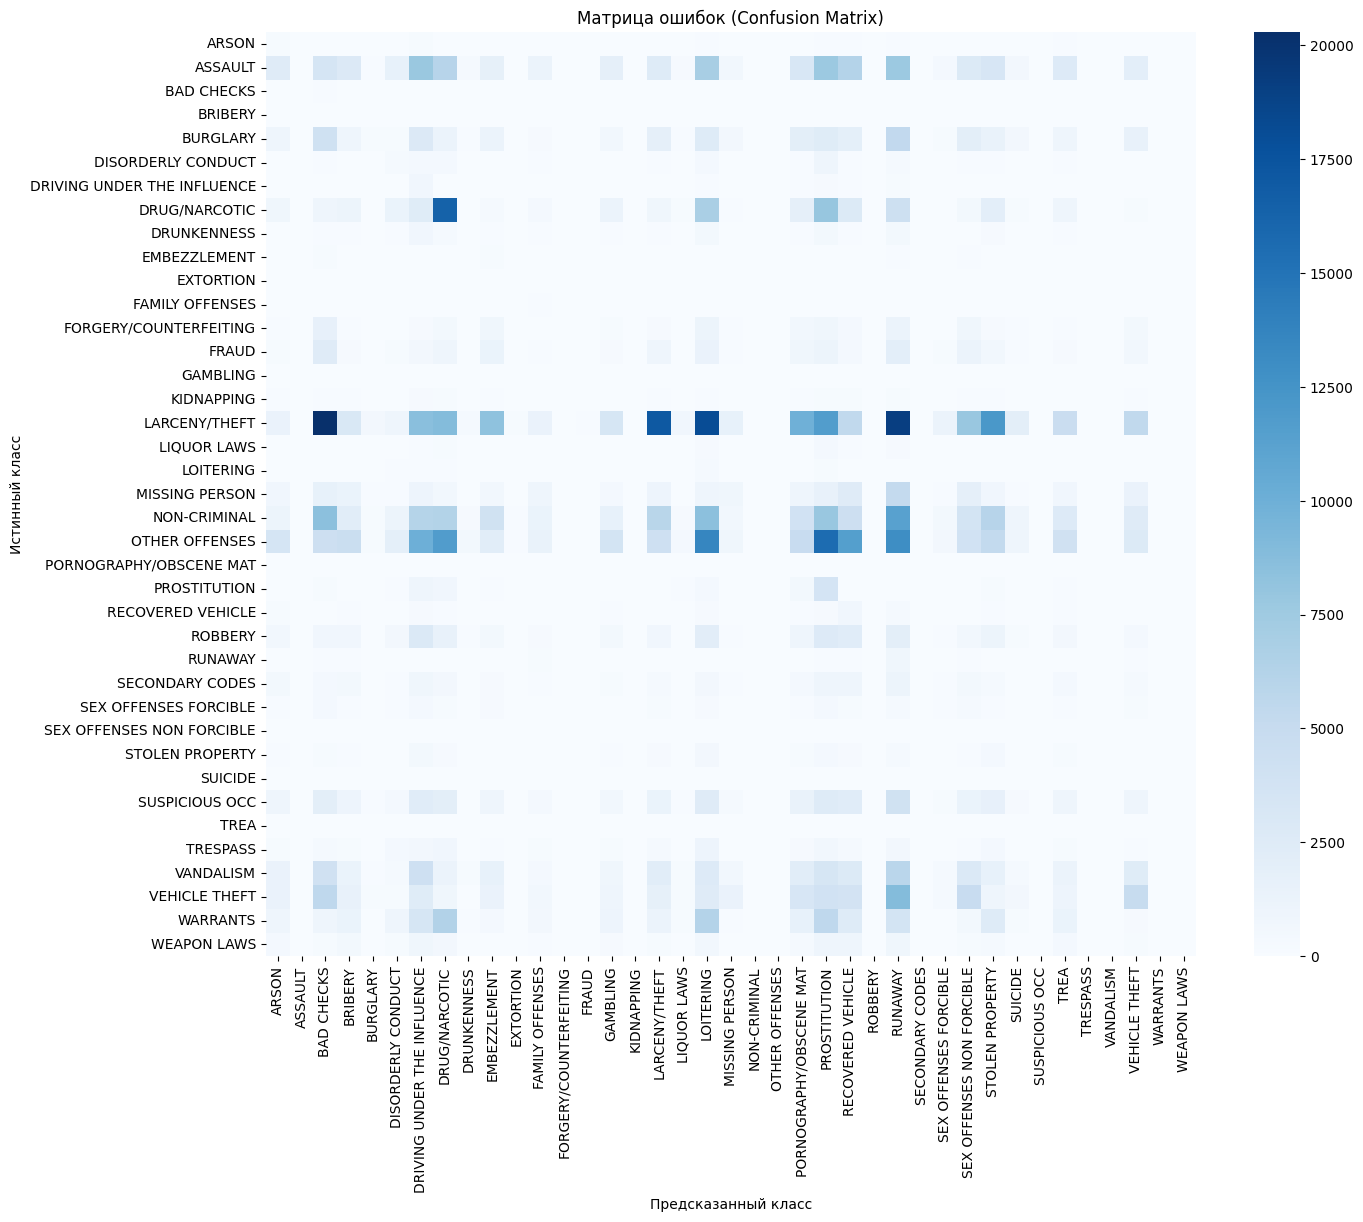

In [ ]:
from sklearn.metrics import log_loss, accuracy_score, f1_score, confusion_matrix

test_with_labels_df = pd.read_csv('train.csv')

test_with_labels_df = create_time_features(test_with_labels_df)

for col in categorical_columns:
    test_with_labels_df[col] = label_encoders[col].transform(test_with_labels_df[col].astype(str))

X_test_with_labels = test_with_labels_df[feature_columns]
y_test_true = test_with_labels_df['Category']

y_test_proba = catboost_model.predict_proba(X_test_with_labels)
y_test_pred = catboost_model.predict(X_test_with_labels)

logloss_test = log_loss(y_test_true, y_test_proba)
accuracy = accuracy_score(y_test_true, y_test_pred)
f1_micro = f1_score(y_test_true, y_test_pred, average='micro')
f1_macro = f1_score(y_test_true, y_test_pred, average='macro')

print(f"LogLoss CatBoost на тестовом наборе: {logloss_test:.6f}")
print(f"Accuracy CatBoost на тестовом наборе: {accuracy:.4f}")
print(f"F1-score (micro) CatBoost на тестовом наборе: {f1_micro:.4f}")
print(f"F1-score (macro) CatBoost на тестовом наборе: {f1_macro:.4f}")

unique_classes = catboost_model.classes_
cm = confusion_matrix(y_test_true, y_test_pred, labels=unique_classes)

plt.figure(figsize=(15, 12))
sns.heatmap(cm, annot=False, fmt='d', cmap='Blues',
            xticklabels=unique_classes, yticklabels=unique_classes)
plt.title('Матрица ошибок (Confusion Matrix)')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()